# M5 Validation: Time-Windowed Latent Editing
End-to-end M5 validation with A2 callback capture and windowed editing.

In [1]:
from pathlib import Path
import torch
from IPython.display import display
from helpers.methods.callbacks import StepLatentRecorder, TimeWindowLatentEditor
from helpers.runtime.inference import generate_prompt_baseline, timed_generate_with_prompt
from helpers.runtime.pipeline import load_flux_pipeline, resolve_runtime_device
from helpers.runtime.utils import flush_namespace
from helpers.runtime.dtype_handler.parsing import resolve_dtype_for_device

WARNING[XFORMERS]: xFormers can't load C++/CUDA extensions. xFormers was built for:
    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.11.0+cu130)
    Python  3.10.11 (you have 3.13.11)
  Please reinstall xformers (see https://github.com/facebookresearch/xformers#installing-xformers)
  Memory-efficient attention, SwiGLU, sparse and more won't be available.
  Set XFORMERS_MORE_DETAILS=1 for more details
W0423 21:38:52.316000 42852 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Error occurred while checking dtype torch.float8_e4m3fn on device cuda: "ufunc_add_CUDA" not implemented for 'Float8_e4m3fn'
Candidate FP8 dtype float8_e4m3fn is not supported on device=cuda
Error occurred while checking dtype torch.float8_e5m2 on device cuda: "ufunc_add_CUDA" not implemented for 'Float8_e5m2'
Candidate FP8 dtype float8_e5m2 is not supported on device=cuda
Falling back from FP8 to torch.float16 on device=cuda; tested candidates=[float8_e4m3fn, float8_e5m2]
Enabled layerwise casting on transformer (storage=torch.float16, compute=torch.bfloat16)
Layerwise casting not enabled; skipping fallback attempt


The module 'Flux2Transformer2DModel' is group offloaded and moving it to cuda via `.to()` is not supported.


Enabled group offloading for text_encoder (offload_type=block_level)
Skipping group offload for vae: CUDA error: out of memory
Search for `cudaErrorMemoryAllocation' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.

Loaded pipeline with transformer group offload enabled (use_stream=True, low_cpu_mem_usage=False, enable_text_encoder_group_offload=True, enable_vae_group_offload=True)
Enabled VAE slicing via vae.enable_slicing()
Enabled VAE tiling via vae.enable_tiling()
Skipping channels-last on vae: CUDA error: out of memory
Search for `cudaErrorMemoryAllocation' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously r

  0%|          | 0/3 [00:00<?, ?it/s]

baseline in 95.76 s -> C:\Users\David\Desktop\thesis\NeLs\project\python\examples\callbacks\outputs\m5_time_window_notebook\m5_baseline.png


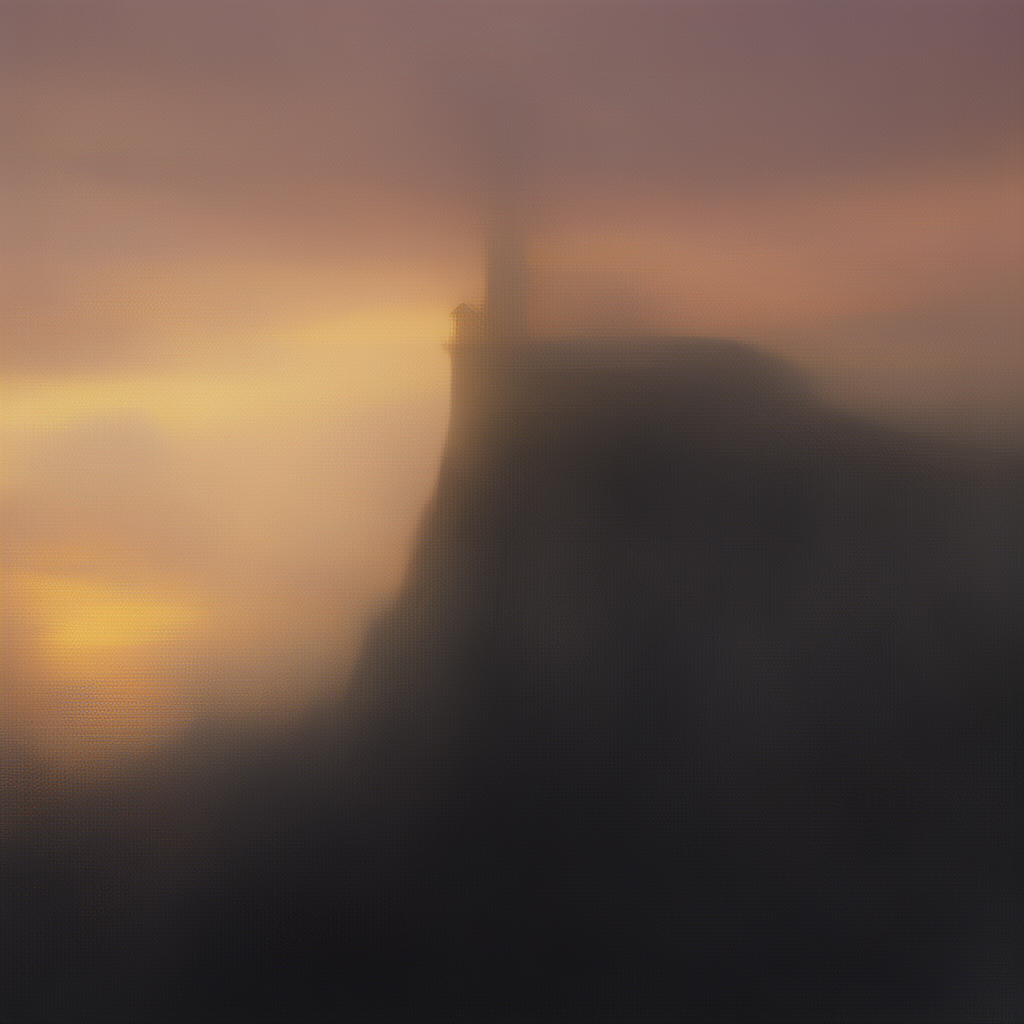

  0%|          | 0/3 [00:00<?, ?it/s]

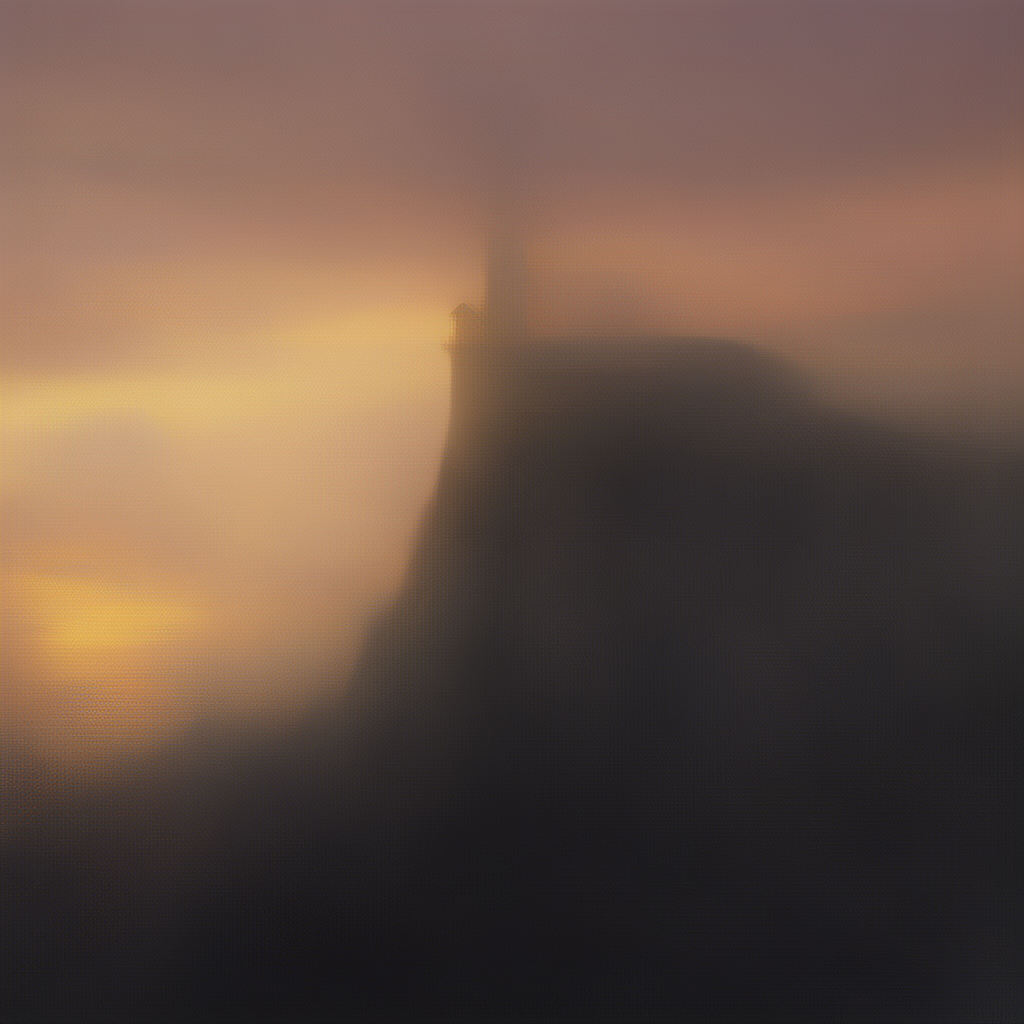

edited generation in 342.71 s -> C:\Users\David\Desktop\thesis\NeLs\project\python\examples\callbacks\outputs\m5_time_window_notebook\m5_time_window_output.png
Captured steps: [0, 1, 2]
Edited steps: [1, 2]
Latent norms: {0: 688.0, 1: 592.0, 2: 358.0}
Before flush: allocated=0.17 GB, reserved=8.43 GB, peak_allocated=7.95 GB
After flush: allocated=0.01 GB, reserved=0.02 GB, peak_allocated=0.01 GB


: 

In [ ]:
output_dir = Path('../python/examples/callbacks/outputs/m5_time_window_notebook').resolve()
output_dir.mkdir(parents=True, exist_ok=True)

device = resolve_runtime_device()
dtype = resolve_dtype_for_device(device=device)

prompt = 'a dramatic cliffside lighthouse during golden hour'
seed = 404
num_inference_steps = 3
guidance_scale = 0.0
try:
    pipe = load_flux_pipeline(
        torch_dtype=dtype,
        device=device,
        offload_mode="group",
        group_offload_type="leaf_level",
        group_use_stream=True,
        group_low_cpu_mem_usage=False,
        enable_text_encoder_group_offload=True,
        text_encoder_group_offload_type="block_level",
        text_encoder_num_blocks_per_group=1,
        enable_vae_group_offload=True,
        vae_group_offload_type="leaf_level",
        vae_num_blocks_per_group=2,
        enable_vae_slicing=True,
        enable_vae_tiling=True,
        enable_layerwise_casting=True,
        layerwise_storage_dtype=None,  # Auto-select supported FP8 or fallback.
        layerwise_fallback_storage_dtype=torch.float16,
        layerwise_compute_dtype=dtype,
        enable_channels_last=True,
        enable_xformers_attention=True,
        enable_torch_compile=False,
        disable_progress_bar=False
    )

    recorder = StepLatentRecorder(store_on_cpu=True, on_hook_error='warn')

    def dampen_edit(latents: torch.Tensor, step: int, timestep: float, callback_kwargs):
        _ = step, timestep, callback_kwargs
        return latents * 0.98

    editor = TimeWindowLatentEditor(
        start_step=1,
        end_step=3,
        edit_fn=dampen_edit,
        on_hook_error='warn',
        clone_before_edit=True,
    )

    def combined_callback(pipe_obj, step_index, timestep, callback_kwargs):
        callback_kwargs = editor.callback(pipe_obj, step_index, timestep, callback_kwargs)
        callback_kwargs = recorder.callback(pipe_obj, step_index, timestep, callback_kwargs)
        return callback_kwargs

    baseline_image, baseline_elapsed, _ = generate_prompt_baseline(
        pipe=pipe,
        prompt=prompt,
        seed=seed,
        device=device,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
    )
    baseline_path = output_dir / 'm5_baseline.png'
    baseline_image.save(baseline_path)

    print(f'baseline in {baseline_elapsed:.2f} s -> {baseline_path}')
    display(baseline_image)

    out, elapsed = timed_generate_with_prompt(
        pipe=pipe,
        prompt=prompt,
        seed=seed,
        device=device,
        callback=combined_callback,
        callback_tensor_inputs=['latents'],
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
    )
    image = out.images[0]

    path = output_dir / 'm5_time_window_output.png'
    image.save(path)

    display(image)
    print(f'edited generation in {elapsed:.2f} s -> {path}')
    print('Captured steps:', recorder.steps())
    print('Edited steps:', editor.applied_steps)
    print('Latent norms:', {step: float(lat.norm().item()) for step, lat in recorder.latents_by_step.items()})
finally:
    flush_namespace(
        globals(),
        "pipe",
        "out",
        "image",
        "baseline_image",
        "recorder",
        "editor",
        verbose=True,
        hard_exit=True
    )